# Material de aula - FACENS - Aprendizado de Máquina

# <center> RESOLUÇÃO DA ATIVIDADE </center>


## Particle Swarm Optimization - Laboratório 04

In [1]:
#CÉLULA PSO-LIB-01
import numpy as np
import math
import matplotlib.pyplot as plt
from enum import Enum
from operator import xor
%matplotlib inline

In [2]:
#CÉLULA PSO-LIB-02
def fitness(particle) :  
    '''
    Esta função calcula a aptidão (custo) de uma dada partícula a partir de seus parâmetros.
    
    Parâmetro
    ---------
    particle -> descritor da partícula, no formato de um dicionário com a seguinte estrutura:
    ({'X' : x, 'Y' : y, 'XBest' : x, 'YBest' : y, 'VX' : vx, 'VY':vy })
    
    Retorno
    -------
    
    O valor de aptidão calculado para a partícula.
    '''
    
    x = particle['X']
    y = particle['Y']
    
    num = (np.sin(np.sqrt(x**2+y**2)))**2 - 0.5
    den = (1 + 0.001*(x**2+y**2)) ** 2
    z = 0.5 - (num / den)

    return z

In [3]:
#CÉLULA PSO-LIB-03
def plot_population(vParticles, generation):
    '''
    Esta função plota o gráfico de um dado bando de partículas, para uma dada geração, em função de suas posições.
    
    Parâmetros
    ----------
     vParticles -> um array de descritores de partículas, cada qual no formato de um dicionário com a seguinte estrutura:
    ({'X' : x, 'Y' : y, 'XBest' : x, 'YBest' : y, 'VX' : vx, 'VY':vy })
    
    generation  -> indicador da geração da população
    
    Retorno
    -------
    N/A
    '''
    xmin =-100
    xmax = 100
    ymin =-100
    ymax = 100
    
    xAxis = []
    yAxis = []
    for particle in vParticles : #pega as partículas do bando        
        x = particle['X']
        y = particle['Y']
        
        xAxis.append(x)
        yAxis.append(y)
    
    plt.figure()
    plt.plot(xAxis, yAxis, 'bo')
    plt.axis([xmin, xmax, ymin, ymax])
    
    plt.xlabel('x')
    plt.ylabel('y')
    sTitle = ('Populacao na geração {}'.format(generation))
    plt.title(sTitle)
    plt.grid()

In [4]:
#CÉLULA PSO-LIB-04
def calcPBest(particle) :
    '''
    Esta função verifica se a posição atual da partícula é melhor que a sua melhor posição de todos os tempos e atualiza a 
    informação, se necessário.
    
    Parâmetro
    ---------
    particle -> descritor da partícula, no formato de um dicionário com a seguinte estrutura:
    ({'X' : x, 'Y' : y, 'XBest' : x, 'YBest' : y, 'VX' : vx, 'VY':vy })
    
    Retorno
    -------
    
    Uma tupla (xBest, yBest) com as coordenadas das melhores posições de todos os tempos de uma dada partícula 
    '''
    xBest = particle['XBest']
    yBest = particle['YBest']
    
    particleBest = {'X' : xBest, 'Y' : yBest, 'XBest' : xBest, 'YBest' : yBest, 'VX' : 0, 'VY':0 }
    
    if (fitness(particle) >= fitness(particleBest)) :
        xBest = particle['X']
        yBest = particle['Y']
                
    return (xBest, yBest)

In [5]:
#CÉLULA PSO-LIB-05
def calcAllPBest(vParticles) :
    '''
    Esta função verifica e atualiza o atributo pBest (a melhor posição de uma partícula) para todas as partículas 
    da população a partir de seus respectivos parâmetros.
    
    Parâmetro
    ---------
    vParticles -> um array de descritores de partículas, cada qual no formato de um dicionário com a seguinte estrutura:
    ({'X' : x, 'Y' : y, 'XBest' : x, 'YBest' : y, 'VX' : vx, 'VY':vy })
    
    Retorno
    -------
    
    Um array de valores de aptidão calculados para todas as partículas, alinhado com o array vParticles.
    '''    
    vParticlesRet = []
    
    for particle in vParticles :
        (x, y) = calcPBest(particle)
        particle['XBest'] = x
        particle['YBest'] = y
                    
        vParticlesRet.append(particle)
    
    return vParticlesRet

In [6]:
#CÉLULA PSO-LIB-06
def calcGBest(vParticles) :
    '''
    Esta função verifica a melhor posição do bando e retorna suas coordenadas.
    
    Parâmetro
    ---------
    vParticles -> array contendo descritores de partícula, no formato de um dicionário com a seguinte estrutura:
    ({'X' : x, 'Y' : y, 'XBest' : x, 'YBest' : y, 'VX' : vx, 'VY':vy })
    
    Retorno
    -------
    
    Um dicionario no formato {'X' : x, 'Y' : y, 'Fitness' : maxFitness} com as coordenadas da melhor posição de todos
    os tempos do bando bem como o valor de fitness associado a esta posição
    '''
    #Inicializa variavel
    calcAllPBest(vParticles)
    maxFitness = fitness(vParticles[0])

    for particle in vParticles :
        x = particle['XBest']
        y = particle['YBest']
        particleBest = {'X' : x, 'Y' : y, 'XBest' : x, 'YBest' : y, 'VX' : 0, 'VY':0 }

        currentFitness = fitness(particleBest)
        if ( currentFitness >= maxFitness ) :
            maxFitness = currentFitness
            gBest = {'X' : x, 'Y' : y, 'Fitness' : maxFitness}
    
    return gBest

# PSO - inicio

# 1 - Criando o enxame de partículas

Utilizando Jupyter e NumPy: escreva a função que cria um enxame de partículas inicial com valores aleatórios no domínio do espaço de busca.

Domínio da função: 
- xmin = -100
- xmax =  100
- ymin = -100
- xmax =  100

In [7]:
#CÉLULA PSO-MAIN-01
#Parâmetros
size_pop   = 100
max_generations = 100
stop_condition = 0.95

#Limites do dominio de definição
x_min = -100
x_max =  100

y_min = -100
y_max =  100


# Cada particula tem dados (X,Y, XBest, YBest)
gBest = {'X' : 0, 'Y' : 0, 'Fitness' : 0}
vParticles = []

deltaT = 1
c1 = 0.2
c2 = 0.3
w  = 0.2

vMax = 500 #limitação de velocidade

#r1 e r2 deverão ser extraídas de uma distribuição uniforme e são atualizadas a cada cálculo de velocidade da população
#as melhores posições, individual e global, são obtidas através da função de fitness

In [8]:
#CÉLULA PSO-MAIN-02
#Inicializando população
vParticles=[]

for _ in range(0, size_pop):
    x   =  x_min + np.random.random() * (x_max - x_min)
    y   =  y_min + np.random.random() * (y_max - y_min)
    vx  = (x_min + np.random.random() * (x_max - x_min)) / deltaT
    vy  = (y_min + np.random.random() * (y_max - y_min)) / deltaT
    vParticles.append({'X' : x, 'Y' : y, 'XBest' : x, 'YBest' : y, 'VX' : vx, 'VY':vy })

[{'Y': 4.296151807479802, 'YBest': 4.296151807479802, 'VX': 29.198655456014734, 'VY': -83.37974368486591, 'XBest': 75.32062449297106, 'X': 75.32062449297106}, {'Y': -15.681433578318078, 'YBest': -15.681433578318078, 'VX': -57.80770458980247, 'VY': 4.456332480252215, 'XBest': -57.579684131708, 'X': -57.579684131708}, {'Y': -78.71776799771592, 'YBest': -78.71776799771592, 'VX': 57.76386114994867, 'VY': 86.32807366249855, 'XBest': 11.471481766946184, 'X': 11.471481766946184}, {'Y': -8.21076602205757, 'YBest': -8.21076602205757, 'VX': -31.854599799384857, 'VY': -68.9520926913308, 'XBest': -46.4180517254134, 'X': -46.4180517254134}, {'Y': 39.4397097227984, 'YBest': 39.4397097227984, 'VX': 5.222313765149167, 'VY': 46.248434398637045, 'XBest': -28.39312996782688, 'X': -28.39312996782688}, {'Y': -67.14186354461584, 'YBest': -67.14186354461584, 'VX': -0.9429917542395714, 'VY': -71.06150522867256, 'XBest': -27.406746407837673, 'X': -27.406746407837673}, {'Y': 56.661876533677145, 'YBest': 56.6618

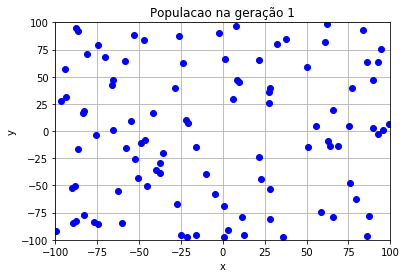

In [9]:
#Teste
plot_population(vParticles, 1)

print(vParticles)

## Validação

plot_population(vParticles, 1)        

print(vParticles)

## Observe a disposição das particulas no dominio. Use populações menores e verifique se todas estão presentes.